<a href="https://colab.research.google.com/github/kshamasahu706-wq/Customer-Churn-Feature-Engineering/blob/main/Responsible_Data_Card_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Responsible Data Card & Fair Machine Learning Project
## Student Support Needs Prediction (Synthetic Demonstration)

**Purpose:** Demonstrate a responsible data-science workflow in Google Colab: dataset creation, data quality checks, exploratory analysis, model training, evaluation, subgroup error analysis, and a completed Responsible Data Card.

> **Important:** This notebook creates a fully synthetic dataset. It contains no real student records and must not be used to make decisions about real students. The model is an educational demonstration only. Any real deployment would require consent, institutional review, domain-expert oversight, validation, and an appeal process.

**Prepared for:** Project / company task demonstration  
**Notebook environment:** Google Colab / Python 3

## 1. Project overview

Educational institutions may want to identify students who could benefit from additional academic support. This project demonstrates how a data team can explore a dataset and estimate a *support-needed indicator* while documenting limitations and risks.

### Project objectives
1. Create a reproducible synthetic dataset.
2. Inspect data types, missing values, duplicates, outliers, and class balance.
3. Explore patterns using visualizations.
4. Train simple baseline and comparison models.
5. Evaluate performance using precision, recall, F1, ROC-AUC, and a confusion matrix.
6. Review calibration and subgroup error rates.
7. Complete a Responsible Data Card and record safeguards.

### Scope and non-goals
- In scope: a technical demonstration of a possible early-support signal.
- Not in scope: grading students, admission decisions, discipline, scholarship decisions, or replacing teachers/counsellors.
- A prediction is not a fact about a student. Human review and student context are essential.

## 2. Set up the environment

In [ ]:
# Most libraries are pre-installed in Google Colab.
import sys, platform, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay
)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("Libraries imported successfully.")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Libraries imported successfully.


## 3. Create the synthetic dataset

The dataset below is generated inside the notebook so that it runs without downloading external files. All rows are artificial. Features are intentionally simple and should not be interpreted as validated educational predictors.

**Target:** `support_needed` (1 = synthetic record flagged as potentially needing support; 0 = otherwise).  
**Illustrative subgroup field:** `region_group` is included only to demonstrate subgroup auditing. It is not used as a model input.

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
n = 1200

study_hours = np.clip(rng.normal(8, 3, n), 0, 20)
attendance_pct = np.clip(rng.normal(78, 13, n), 25, 100)
assignment_completion = np.clip(rng.normal(0.72, 0.20, n), 0, 1)
prior_score = np.clip(rng.normal(68, 14, n), 10, 100)
internet_access = rng.choice(["Reliable", "Limited"], size=n, p=[0.78, 0.22])
region_group = rng.choice(["Group A", "Group B", "Group C"], size=n, p=[0.50, 0.30, 0.20])

# Synthetic probability rule; deliberately not a real-world validated relationship.
logit = (
    1.8
    - 0.11 * study_hours
    - 0.025 * attendance_pct
    - 1.8 * assignment_completion
    - 0.018 * prior_score
    + 0.35 * (internet_access == "Limited")
)
prob = 1 / (1 + np.exp(-logit))
support_needed = rng.binomial(1, prob)

df = pd.DataFrame({
    "study_hours_per_week": study_hours.round(1),
    "attendance_pct": attendance_pct.round(1),
    "assignment_completion_rate": assignment_completion.round(2),
    "prior_score": prior_score.round(1),
    "internet_access": internet_access,
    "region_group": region_group,
    "support_needed": support_needed
})

# Introduce a small amount of missingness for data-quality demonstration.
for col in ["study_hours_per_week", "attendance_pct", "internet_access"]:
    idx = rng.choice(df.index, size=int(0.025 * n), replace=False)
    df.loc[idx, col] = np.nan

# Add a few duplicate rows to demonstrate duplicate checks.
df = pd.concat([df, df.sample(8, random_state=RANDOM_STATE)], ignore_index=True)

print("Dataset shape:", df.shape)
display(df.head(10))

Dataset shape: (1208, 7)


,study_hours_per_week,attendance_pct,assignment_completion_rate,prior_score,internet_access,region_group,support_needed
0,8.9,60.8,0.63,81.6,Reliable,Group A,0
1,4.9,71.7,0.92,100.0,Reliable,Group A,0
2,10.3,83.5,0.78,48.5,NaN,Group B,0
3,10.8,76.7,0.58,88.4,Limited,Group A,0
4,2.1,69.5,0.55,69.0,Reliable,Group A,0
5,4.1,69.2,0.39,79.3,Reliable,Group A,0
6,8.4,68.7,0.78,44.9,Reliable,Group A,1
7,7.1,66.6,0.65,88.6,Reliable,Group A,0
8,7.9,100.0,0.25,79.0,Reliable,Group B,0
9,5.4,81.9,0.61,67.5,Reliable,Group A,0


## 4. Data dictionary

In [ ]:
data_dictionary = pd.DataFrame([
    ["study_hours_per_week", "Numeric", "Synthetic hours studied per week", "Model input"],
    ["attendance_pct", "Numeric", "Synthetic attendance percentage (0–100)", "Model input"],
    ["assignment_completion_rate", "Numeric", "Synthetic fraction of assignments completed (0–1)", "Model input"],
    ["prior_score", "Numeric", "Synthetic prior assessment score (0–100)", "Model input"],
    ["internet_access", "Categorical", "Synthetic access category", "Model input; may reflect access inequality"],
    ["region_group", "Categorical", "Synthetic group used for auditing only", "Audit field; excluded from model"],
    ["support_needed", "Binary target", "Synthetic label generated by an artificial rule", "Prediction target"]
], columns=["Feature", "Type", "Description", "Role"])
display(data_dictionary)

,Feature,Type,Description,Role
0,study_hours_per_week,Numeric,Synthetic hours studied per week,Model input
1,attendance_pct,Numeric,Synthetic attendance percentage (0–100),Model input
2,assignment_completion_rate,Numeric,Synthetic fraction of assignments completed (0–1),Model input
3,prior_score,Numeric,Synthetic prior assessment score (0–100),Model input
4,internet_access,Categorical,Synthetic access category,Model input; may reflect access inequality
5,region_group,Categorical,Synthetic group used for auditing only,Audit field; excluded from model
6,support_needed,Binary target,Synthetic label generated by an artificial rule,Prediction target


## 5. Data quality checks

In [ ]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("\\nMissing values:")
missing = df.isna().sum().to_frame("missing_count")
missing["missing_percent"] = (missing["missing_count"] / len(df) * 100).round(2)
display(missing)

print("Exact duplicate rows:", df.duplicated().sum())
print("\\nNumeric summary:")
display(df.describe().T)

print("\\nTarget balance (including percentage):")
balance = df["support_needed"].value_counts().rename("count").to_frame()
balance["percent"] = (balance["count"] / len(df) * 100).round(2)
display(balance)

Data types:


,dtype
study_hours_per_week,float64
attendance_pct,float64
assignment_completion_rate,float64
prior_score,float64
internet_access,object
region_group,object
support_needed,int64


\nMissing values:


,missing_count,missing_percent
study_hours_per_week,31,2.57
attendance_pct,30,2.48
assignment_completion_rate,0,0.00
prior_score,0,0.00
internet_access,30,2.48
region_group,0,0.00
support_needed,0,0.00


Exact duplicate rows: 8
\nNumeric summary:


,count,mean,std,min,25%,50%,75%,max
study_hours_per_week,1177.0,7.966525,2.935949,0.00,6.000,8.00,9.800,17.5
attendance_pct,1178.0,77.026061,12.781296,38.20,68.625,78.00,85.975,100.0
assignment_completion_rate,1208.0,0.719901,0.183752,0.15,0.590,0.73,0.870,1.0
prior_score,1208.0,67.626573,13.795240,24.00,58.200,67.45,76.325,100.0
support_needed,1208.0,0.043874,0.204900,0.00,0.000,0.00,0.000,1.0


\nTarget balance (including percentage):


,count,percent
support_needed,,
0,1155,95.61
1,53,4.39


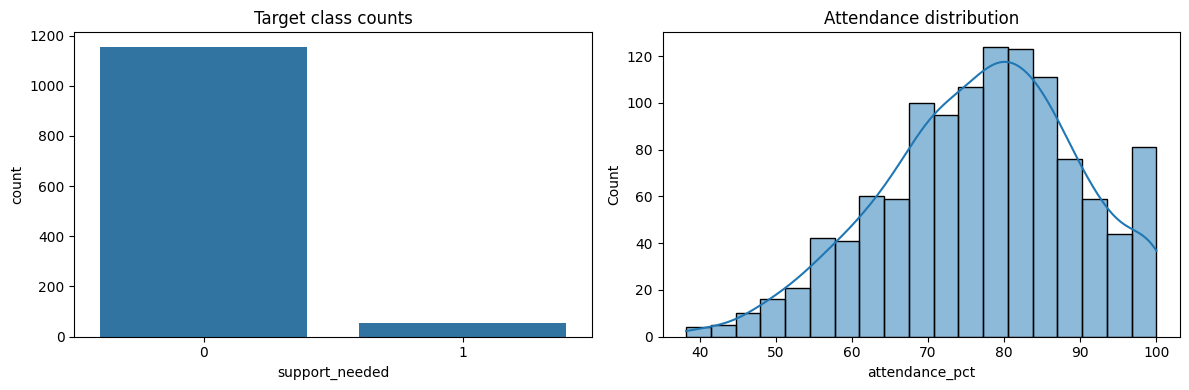

,feature,IQR_lower,IQR_upper,flagged_rows
0,study_hours_per_week,0.3000,15.5000,11
1,attendance_pct,42.6000,112.0000,7
2,assignment_completion_rate,0.1700,1.2900,1
3,prior_score,31.0125,103.5125,8


In [ ]:
# Visual checks
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="support_needed", ax=axes[0])
axes[0].set_title("Target class counts")
sns.histplot(data=df, x="attendance_pct", kde=True, ax=axes[1])
axes[1].set_title("Attendance distribution")
plt.tight_layout()
plt.show()

# Outlier scan using the IQR rule (flagging, not automatically deleting).
numeric_cols = ["study_hours_per_week", "attendance_pct",
                "assignment_completion_rate", "prior_score"]
outlier_report = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_report.append([col, lower, upper, int(count)])
display(pd.DataFrame(outlier_report, columns=["feature", "IQR_lower", "IQR_upper", "flagged_rows"]))

### Data quality interpretation
- Missing values are measured before imputation.
- Duplicate rows are identified; exact duplicates are removed for this demonstration.
- IQR flags are prompts for investigation, not proof that a value is invalid.
- Class balance should be checked before interpreting accuracy.
- The synthetic target is generated from a rule, so strong results would only show that a model can learn this artificial rule.

## 6. Prepare data without leakage

In [ ]:
# Remove exact duplicates for the modeling demonstration.
clean_df = df.drop_duplicates().copy()

TARGET = "support_needed"
AUDIT_FIELD = "region_group"  # kept aside for subgroup analysis; not a model feature

X = clean_df.drop(columns=[TARGET, AUDIT_FIELD])
y = clean_df[TARGET].astype(int)
audit_group = clean_df[AUDIT_FIELD].fillna("Unknown")

numeric_features = ["study_hours_per_week", "attendance_pct",
                    "assignment_completion_rate", "prior_score"]
categorical_features = ["internet_access"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(
    X, y, audit_group, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Target rate - train:", round(y_train.mean(), 3))
print("Target rate - test:", round(y_test.mean(), 3))

Training rows: 900 | Test rows: 300
Target rate - train: 0.044
Target rate - test: 0.043


**Leakage prevention:** preprocessing is placed inside an sklearn pipeline and fitted only on training data. The audit field is held separately and is not used to train the model. The target itself is never included in the input features.

## 7. Train baseline and comparison models

In [ ]:
models = {
    "Logistic Regression (baseline)": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced",
                                     random_state=RANDOM_STATE))
    ]),
    "Random Forest (comparison)": Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=250, min_samples_leaf=4,
            class_weight="balanced", random_state=RANDOM_STATE
        ))
    ])
}

fitted_models = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    print(name, "trained.")

Logistic Regression (baseline) trained.
Random Forest (comparison) trained.


## 8. Evaluate model performance

In [ ]:
results = []
predictions = {}
probabilities = {}

for name, model in fitted_models.items():
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    predictions[name] = pred
    probabilities[name] = score
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score)
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
display(results_df)

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression (baseline),0.630,0.055,0.462,0.098,0.598
Random Forest (comparison),0.953,0.000,0.000,0.000,0.579


              precision    recall  f1-score   support

           0       0.96      0.64      0.77       287
           1       0.05      0.46      0.10        13

    accuracy                           0.63       300
   macro avg       0.51      0.55      0.43       300
weighted avg       0.92      0.63      0.74       300



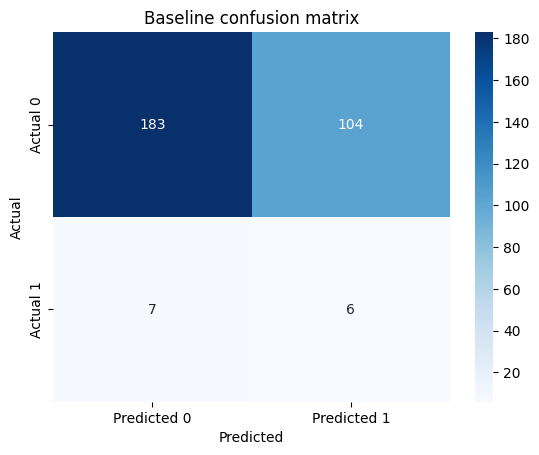

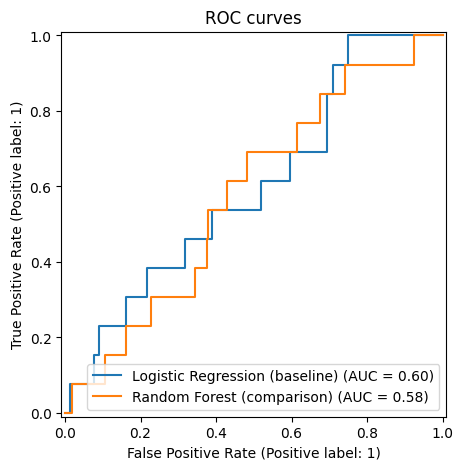

In [ ]:
# Confusion matrix and detailed report for the baseline model.
baseline_name = "Logistic Regression (baseline)"
baseline_pred = predictions[baseline_name]

print(classification_report(y_test, baseline_pred, zero_division=0))
cm = confusion_matrix(y_test, baseline_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title("Baseline confusion matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax, name=name)
ax.set_title("ROC curves")
plt.show()

### How to read the metrics
- **Precision:** among records flagged positive, how many were positive in the synthetic test labels.
- **Recall:** among positive test labels, how many were detected.
- **F1:** harmonic mean of precision and recall.
- **ROC-AUC:** ranking ability across thresholds.
- **Confusion matrix:** separates true positives, false positives, true negatives, and false negatives.

There is no universal acceptable score. The appropriate trade-off depends on the real use case and the consequences of errors. Here, results are only illustrative because the data and labels are synthetic.

## 9. Calibration check

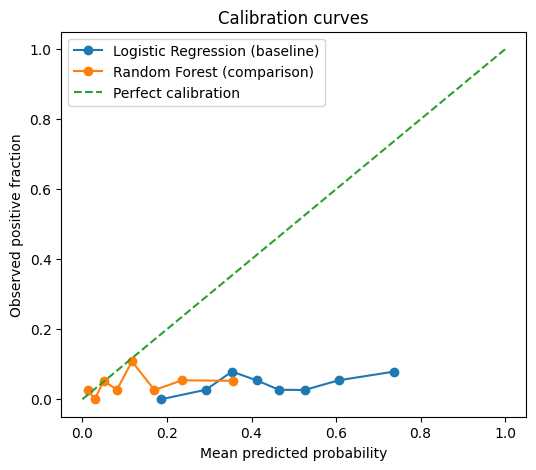

In [ ]:
# Calibration curve: do predicted probabilities correspond to observed positive rates?
plt.figure(figsize=(6, 5))
for name, score in probabilities.items():
    frac_pos, mean_pred = calibration_curve(y_test, score, n_bins=8, strategy="quantile")
    plt.plot(mean_pred, frac_pos, marker="o", label=name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Calibration curves")
plt.legend()
plt.show()

## 10. Subgroup error analysis

This section checks performance by the synthetic `region_group` field. The field is used for auditing only and is excluded from model training. Small subgroup sample sizes can make estimates unstable; always show group counts alongside rates.

In [ ]:
audit_rows = []
for group in sorted(group_test.unique()):
    mask = (group_test == group).to_numpy()
    y_g = y_test.to_numpy()[mask]
    p_g = baseline_pred[mask]
    n_g = int(mask.sum())
    if n_g == 0:
        continue
    audit_rows.append({
        "Audit group": group,
        "N": n_g,
        "Positive label rate": y_g.mean(),
        "Predicted positive rate": p_g.mean(),
        "Recall / TPR": recall_score(y_g, p_g, zero_division=0),
        "False positive rate": (
            ((p_g == 1) & (y_g == 0)).sum() / max((y_g == 0).sum(), 1)
        ),
        "Precision": precision_score(y_g, p_g, zero_division=0)
    })

audit_df = pd.DataFrame(audit_rows).set_index("Audit group").round(3)
display(audit_df)

,N,Positive label rate,Predicted positive rate,Recall / TPR,False positive rate,Precision
Audit group,,,,,,
Group A,146,0.041,0.315,0.500,0.307,0.065
Group B,106,0.057,0.406,0.333,0.410,0.047
Group C,48,0.021,0.438,1.000,0.426,0.048


### Fairness interpretation and limitations
- Differences between groups are signals for investigation, not automatic proof of discrimination or fairness.
- Check sample sizes, data collection, label quality, context, and uncertainty.
- Do not use group membership to deny support or opportunity.
- A real fairness assessment should be designed with affected communities and qualified reviewers; it may require additional metrics and legal review.

## 11. Error analysis

In [ ]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test.values
error_analysis["predicted"] = baseline_pred
error_analysis["predicted_probability"] = probabilities[baseline_name]
error_analysis["audit_group"] = group_test.values
error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual"] == 1) & (error_analysis["predicted"] == 0),
        (error_analysis["actual"] == 0) & (error_analysis["predicted"] == 1)
    ],
    ["False Negative", "False Positive"],
    default="Correct"
)
display(error_analysis[error_analysis["error_type"] != "Correct"].head(20))
print("Error counts:")
display(error_analysis["error_type"].value_counts().to_frame("count"))

,study_hours_per_week,attendance_pct,assignment_completion_rate,prior_score,internet_access,actual,predicted,predicted_probability,audit_group,error_type
140,9.2,67.6,0.82,45.8,Reliable,0,1,0.684976,Group C,False Positive
127,4.4,57.3,0.65,76.9,Limited,0,1,0.621480,Group C,False Positive
594,4.2,53.9,0.62,85.9,Reliable,0,1,0.609233,Group B,False Positive
724,5.2,77.3,0.77,54.9,Reliable,0,1,0.631025,Group B,False Positive
1170,4.6,63.7,0.87,70.8,Reliable,0,1,0.625179,Group A,False Positive
1130,5.3,66.3,1.00,65.8,Reliable,0,1,0.618066,Group B,False Positive
1009,9.1,72.4,0.71,62.0,Reliable,0,1,0.509237,Group A,False Positive
108,10.5,41.9,0.90,66.0,Reliable,0,1,0.699884,Group A,False Positive
1026,1.5,80.0,0.80,60.4,Reliable,0,1,0.655071,Group A,False Positive
313,9.3,52.0,0.49,49.5,Reliable,0,1,0.788714,Group C,False Positive


Error counts:


,count
error_type,
Correct,189
False Positive,104
False Negative,7


## 12. Threshold and human-review considerations

A probability threshold of 0.5 is only a default convention, not a policy recommendation. Changing it changes false positives and false negatives. In a real student-support setting, any alert should lead only to a supportive conversation or an offer of resources—not a penalty or an automatic decision.

Before any real-world pilot:
1. Define the support intervention and who is responsible for reviewing alerts.
2. Consult students, educators, privacy staff, and relevant stakeholders.
3. Obtain appropriate permission and provide clear notice.
4. Test on representative, consented, appropriately governed data.
5. Monitor subgroup outcomes and model drift.
6. Provide a way to correct records, challenge an alert, and opt out where applicable.
7. Stop use if harms or unacceptable disparities are found.

## 13. Completed Responsible Data Card

### Dataset purpose
This synthetic dataset demonstrates whether a basic model can identify records assigned an artificial support-needed label. It may support learning and workflow prototyping only. It must not make or influence real grading, admissions, discipline, scholarship, employment, or other consequential decisions.

### Provenance and permission
All records are generated in this notebook using a fixed random seed. No real student data, external dataset, or personal information is used. The synthetic data may be used for educational demonstration. If replacing it with real data, document the source, collection purpose, legal basis, consent/notice, licence, retention period, and access controls before analysis.

### Population and representation
The dataset contains 1,200 generated rows plus 8 deliberately duplicated rows before cleaning. `region_group` has three artificial categories. These categories do not represent actual geographic, cultural, or demographic populations. The sampling process is random and artificial; it does not represent any institution or student population. Representation and imbalance must be reassessed for any real dataset.

### Features and target
- `study_hours_per_week`: synthetic weekly study hours.
- `attendance_pct`: synthetic attendance percentage.
- `assignment_completion_rate`: synthetic completion fraction.
- `prior_score`: synthetic prior score.
- `internet_access`: synthetic access category; may act as a proxy for socioeconomic or infrastructure differences in real settings.
- `region_group`: synthetic audit-only group; excluded from model inputs.
- `support_needed`: artificial binary target generated from a mathematical rule, not from real student outcomes.

Potential leakage includes accidentally using the target or variables created after the outcome. The pipeline fits imputation, scaling, and encoding on training data only.

### Quality checks
The notebook reports missingness, duplicates, descriptive statistics, target balance, and IQR-based outlier flags. Exact duplicate rows are removed before train/test splitting. Missing values are imputed inside the training pipeline. A stratified holdout split is used. Results remain dependent on the synthetic generation process.

### Risks and safeguards
- **Bias / representation:** synthetic groups are not representative; do not generalize.
- **Privacy:** no real personal data is included; protect and minimize data if using real records.
- **Misuse:** prohibit punitive or high-stakes use.
- **False positives:** may create unnecessary concern; require supportive human review.
- **False negatives:** may miss students who need help; keep ordinary support channels open to everyone.
- **Proxy risk:** internet access may reflect unequal resources; investigate before any real use.
- **Automation risk:** never treat the score as a decision or diagnosis.

### Intended evaluation
The notebook establishes logistic regression as a baseline and random forest as a comparison. It reports accuracy, precision, recall, F1, ROC-AUC, confusion matrix, calibration curves, subgroup recall, false-positive rate, and precision. Error analysis lists false positives and false negatives. A real deployment would require pre-registered acceptance criteria, confidence intervals, external validation, stakeholder review, and ongoing monitoring.

## 14. Reproducibility and project summary

In [ ]:
print("Final project summary")
print("---------------------")
print("Rows before duplicate removal:", len(df))
print("Rows after duplicate removal:", len(clean_df))
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\\nModel comparison:")
display(results_df)
print("\\nSubgroup audit:")
display(audit_df)

Final project summary
---------------------
Rows before duplicate removal: 1208
Rows after duplicate removal: 1200
Training set: (900, 5)
Test set: (300, 5)
\nModel comparison:


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression (baseline),0.630,0.055,0.462,0.098,0.598
Random Forest (comparison),0.953,0.000,0.000,0.000,0.579


\nSubgroup audit:


,N,Positive label rate,Predicted positive rate,Recall / TPR,False positive rate,Precision
Audit group,,,,,,
Group A,146,0.041,0.315,0.500,0.307,0.065
Group B,106,0.057,0.406,0.333,0.410,0.047
Group C,48,0.021,0.438,1.000,0.426,0.048


### Conclusion
This project demonstrates an end-to-end responsible machine-learning workflow using a synthetic educational-support dataset. It includes data quality checks, exploratory analysis, leakage-aware preprocessing, baseline and comparison models, evaluation, calibration, subgroup auditing, and error analysis.

The main lesson is that model performance alone is not enough. Data provenance, representation, privacy, intended use, error consequences, fairness, human oversight, and ongoing monitoring must be considered together.

### Limitations
1. Data and labels are entirely synthetic.
2. The artificial target rule makes the task easier and unlike real educational outcomes.
3. No real-world validity, fairness, or causal claim can be made.
4. Subgroup results are illustrative and may be unstable.
5. No production deployment, personal data processing, or automated decision system is created.

### Future improvements
- Replace synthetic data only with properly authorized, documented data.
- Co-design intended use with students and educators.
- Add confidence intervals and external validation.
- Evaluate additional fairness and calibration measures.
- Conduct privacy, security, legal, and ethical review.
- Monitor drift and create a documented human appeal process.

---
**End of Project**